# EDA: Análise Exploratória de Dados Meteorológicos (INMET)

Este notebook demonstra a análise de séries temporais utilizando dados ingeridos via pipeline ETL no TimescaleDB.

## Conectando ao DB

In [40]:
from sqlalchemy import create_engine
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from dotenv import load_dotenv

sns.set_theme(style="whitegrid")

# Carrega variáveis de ambiente
load_dotenv('../.env')

engine = create_engine(os.getenv('DATABASE_URL'))

## Análises e Estatísticas

### 1. Temperatura média por região

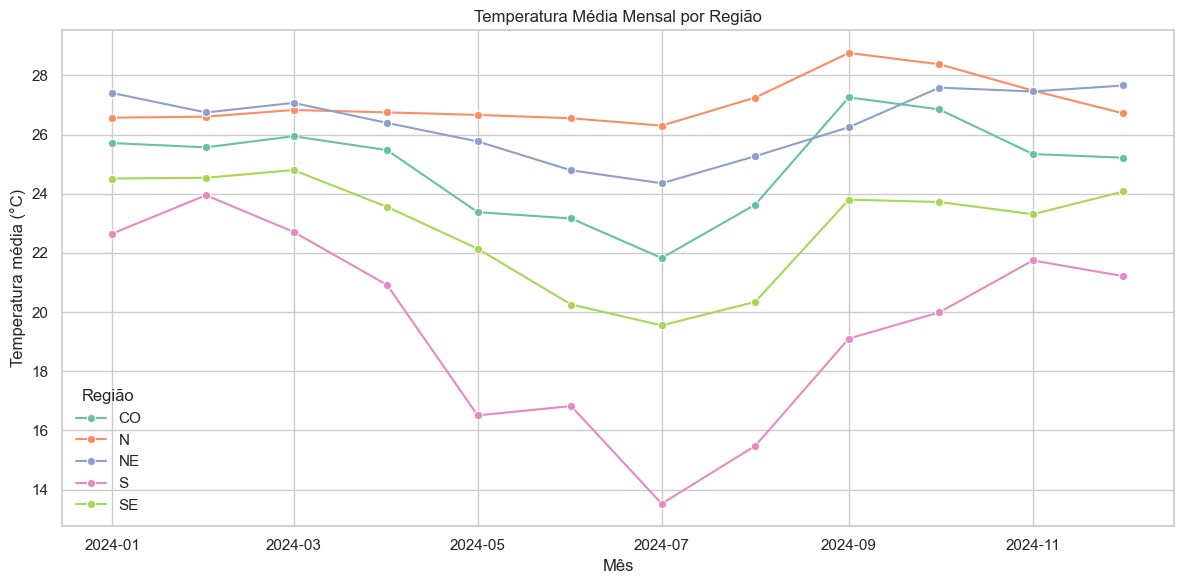

In [57]:
query = """
SELECT 
    time_bucket('1 month', data_hora) AS mes,
    avg(temp_ar) AS temp_media,
    regiao
FROM dados_estacoes
GROUP BY mes, regiao
ORDER BY mes, regiao;
"""

df = pd.read_sql(query, engine)

fig, ax = plt.subplots(figsize=(12, 6))

sns.lineplot(
    data=df,
    x="mes",
    y="temp_media",
    hue="regiao",
    marker="o",
    palette="Set2",
    ax=ax
 )

ax.set_title('Temperatura Média Mensal por Região')
ax.set_xlabel('Mês')
ax.set_ylabel('Temperatura média (°C)')
ax.legend(title='Região')
fig.tight_layout()
plt.show()

### 2. Precipitação acumulada por estado

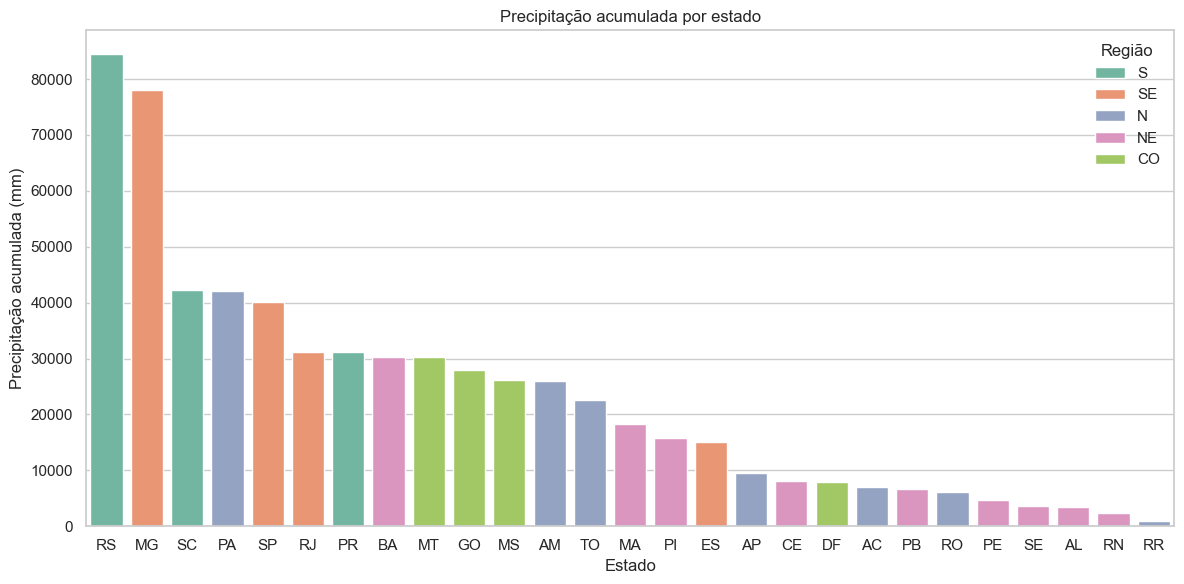

In [55]:
query = """
SELECT
    estado,
    regiao,
    SUM(precipitacao) AS precipitacao
FROM dados_estacoes
GROUP BY estado, regiao
ORDER BY precipitacao DESC;
"""

df = pd.read_sql(query, engine)
fig, ax = plt.subplots(figsize=(12, 6))

sns.barplot(
    data=df,
    x="estado",
    y="precipitacao",
    hue="regiao",
    palette="Set2",
    dodge=False,
    ax=ax
 )

ax.set_title("Precipitação acumulada por estado")
ax.set_xlabel("Estado")
ax.set_ylabel("Precipitação acumulada (mm)")
ax.legend(title="Região")
fig.tight_layout()
plt.show()